# MODEL_CLUSTER — Experts démographiques + catégories

Objectif : tester une **division en mini-modèles** (sexe, âge, catégories films) puis les **rassembler**.

## Critique de l'hypothèse « cascade »

L'idée naïve *homme → âge → genres → assemblage* est fragile :

1. **Sexe / âge ne sont pas des cibles** : en produit on les connaît déjà. Ce sont des **filtres / poids** pour choisir des voisins, pas une classification.
2. **Cascade dure = erreurs en série** : un mauvais cut en amont appauvrit tout le reste. Sur MovieLens, les femmes sont ~25 % des notes → segments trop petits.
3. **Pas d'interactions** : « jeune femme Sci-Fi » n'est pas l'intersection séquentielle des trois listes.
4. **Signal démo souvent faible** (cf. `MODEL_BASELINE`) : des experts purement démo seuls battent rarement un CF global.
5. **Catégories = films** : le bon cluster est un **KMeans films × genres**, pas un cluster users uniquement démo.

## Hypothèse corrigée

Trois **experts de ranking en parallèle**, puis **fusion soft de rangs** (mixture-of-experts). Fallback User–CF global si un segment a trop peu de voisins.


## 1. Chargement et split

Même périmètre que l'EDA / `MODEL_BASELINE` : exclusion `occupation` / `unknown`.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
from scipy import stats
import matplotlib.pyplot as plt

RANDOM_STATE = 38
LIKED_THRESHOLD = 4
MAX_SEEDS = 3

TRAIN_FRAC = 0.25
MIN_SUPPORT = 22
CF_N_USER = 310
AGE_BAND = 10          # ± ans pour ExpertÂge
MIN_SEG_USERS = 15     # fallback si segment trop petit
N_CLUSTERS = 12        # KMeans films × genres
EXPERT_POOL = 80
W_SEX, W_AGE, W_CAT = 1 / 3, 1 / 3, 1 / 3
GENRE_BOOST = 1.15

np.random.seed(RANDOM_STATE)

GENRES = [
    "Action", "Adventure", "Animation", "Children's", "Comedy", "Crime",
    "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror", "Musical",
    "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western",
]

DATA_DIR = next(
    (p for p in [Path("dataset"), Path("../dataset")] if (p / "u.data.csv").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("dataset/ introuvable")

notes = pd.read_csv(DATA_DIR / "u.data.csv")
films = pd.read_csv(DATA_DIR / "u.item.csv")
users = pd.read_csv(DATA_DIR / "u.user.csv", dtype={"zip_code": "string"}).drop(
    columns=["occupation"], errors="ignore"
)

df = notes.merge(users, on="user_id", how="left").merge(
    films, left_on="item_id", right_on="movie_id", how="left"
)
df = df.loc[df["unknown"] != 1].drop(columns=["unknown"]).copy()
df["genres"] = df[GENRES].apply(lambda row: [g for g in GENRES if row[g] == 1], axis=1)

print(f"Notes : {len(df):,} | users : {df['user_id'].nunique()} | films : {df['item_id'].nunique()}")
display(df[["user_id", "item_id", "rating", "age", "gender", "title", "genres"]].head(3))


Notes : 99,990 | users : 943 | films : 1680


,user_id,item_id,rating,age,gender,title,genres
0,196,242,3,49,M,Kolya (1996),[Comedy]
1,186,302,3,39,F,L.A. Confidential (1997),"[Crime, Film-Noir, Mystery, Thriller]"
2,22,377,1,25,M,Heavyweights (1994),"[Children's, Comedy]"


In [2]:
train = df.sample(frac=TRAIN_FRAC, random_state=RANDOM_STATE)
test = df.drop(train.index)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)
print(f"Train {len(train):,} | Test {len(test):,}")

movies = df.drop_duplicates("item_id").set_index("item_id")
movie_genres = movies["genres"].to_dict()
movie_title = movies["title"].to_dict()
film_genre_X = movies[GENRES].astype(float)
all_movie_ids = film_genre_X.index.to_numpy()
print(f"Films catalogue : {len(all_movie_ids)}")


Train 24,998 | Test 74,992
Films catalogue : 1680


## 2. Stats train + cas d'évaluation produit


In [3]:
film_stats = (
    train.groupby("item_id")["rating"]
    .agg(n_ratings="count", mean_rating="mean")
    .reset_index()
)
eligible = film_stats.loc[film_stats["n_ratings"] >= MIN_SUPPORT].set_index("item_id")
mean_rating = eligible["mean_rating"]
print(f"Films eligible (>= {MIN_SUPPORT} notes) : {len(eligible)}")

liked_train = train.loc[train["rating"] >= LIKED_THRESHOLD]
liked_test = test.loc[test["rating"] >= LIKED_THRESHOLD]
train_counts = train.groupby("item_id").size()
cand_A = liked_train.copy()
cand_A["pop"] = cand_A["item_id"].map(train_counts)


def _get_top_seeds(df_u, max_n=MAX_SEEDS):
    sorted_u = df_u.sort_values(["rating", "pop"], ascending=[False, False])
    return list(sorted_u["item_id"].unique()[:max_n])


seeds_per_user = (
    cand_A.groupby("user_id", group_keys=False)
    .apply(_get_top_seeds)
    .rename("query_ids")
)
user_demo = train.drop_duplicates("user_id").set_index("user_id")[["age", "gender"]]
relevant = liked_test.groupby("user_id")["item_id"].apply(set).rename("relevant_ids")

eval_cases = pd.concat([seeds_per_user, user_demo, relevant], axis=1, join="inner").reset_index()
eval_cases["relevant_ids"] = eval_cases.apply(
    lambda r: r["relevant_ids"] - set(r["query_ids"]), axis=1
)
eval_cases = eval_cases.loc[eval_cases["relevant_ids"].map(len) > 0].reset_index(drop=True)
print(f"Cas d'évaluation (1-{MAX_SEEDS} films) : {len(eval_cases)}")
display(eval_cases.head(3))


Films eligible (>= 22 notes) : 405
Cas d'évaluation (1-3 films) : 934


,user_id,query_ids,age,gender,relevant_ids
0,1,"[50, 174, 89]",24,M,"{1, 3, 9, 12, 14, 15, 16, 18, 19, 22, 23, 28, ..."
1,2,"[302, 311, 286]",53,F,"{1, 13, 14, 269, 272, 273, 275, 277, 279, 25, ..."
2,3,"[181, 329]",23,M,"{320, 321, 260, 327, 328, 331, 340, 342, 344, ..."


## 3. Structures CF + KMeans catégories (films × genres)


In [4]:
liked_by_user = (
    train.loc[train["rating"] >= LIKED_THRESHOLD]
    .groupby("user_id")[["item_id", "rating"]]
    .apply(lambda x: list(zip(x["item_id"], x["rating"])))
    .to_dict()
)

fans_of = {
    mid: list(
        zip(
            grp["user_id"].to_numpy(),
            grp["rating"].to_numpy(),
            grp["age"].to_numpy(),
            grp["gender"].to_numpy(),
        )
    )
    for mid, grp in train.loc[train["rating"] >= LIKED_THRESHOLD].groupby("item_id")
}

# KMeans sur genres des films vus en train (évite fuite catalogue test-only)
train_movie_ids = train["item_id"].unique()
X_km = film_genre_X.loc[film_genre_X.index.isin(train_movie_ids)]
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_km.values)
film_cluster = dict(zip(X_km.index.astype(int), cluster_labels.astype(int)))

# films hors train → cluster du centroïde le plus proche
missing = [m for m in all_movie_ids if int(m) not in film_cluster]
if missing:
    pred = kmeans.predict(film_genre_X.loc[missing].values)
    for mid, lab in zip(missing, pred):
        film_cluster[int(mid)] = int(lab)

print(f"User–CF : {len(liked_by_user)} users likers | fans_of = {len(fans_of)} films")
print(f"KMeans : {N_CLUSTERS} clusters sur {len(X_km)} films train")
print(pd.Series(cluster_labels).value_counts().sort_index().to_dict())


User–CF : 934 users likers | fans_of = 1163 films
KMeans : 12 clusters sur 1450 films train
{0: 79, 1: 77, 2: 51, 3: 425, 4: 110, 5: 268, 6: 98, 7: 43, 8: 130, 9: 31, 10: 58, 11: 80}


## 4. Recommenders — baseline + 3 experts + fusion soft


In [5]:
def _seen(query_ids, liked_train_ids=None):
    if isinstance(query_ids, (int, np.integer)):
        seeds = {int(query_ids)}
    else:
        seeds = set(int(x) for x in query_ids)
    s = set(liked_train_ids) if liked_train_ids is not None else set()
    return s.union(seeds), seeds


def recommend_baseline(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None):
    seen, seeds = _seen(query_ids, liked_train_ids)
    union_g = set()
    for qid in seeds:
        union_g.update(movie_genres.get(qid, []))
    if not union_g:
        return []
    scores = [
        (mid, float(m))
        for mid, m in mean_rating.items()
        if mid not in seen and union_g & set(movie_genres.get(mid, []))
    ]
    scores.sort(key=lambda x: (-x[1], x[0]))
    return [m for m, _ in scores[:k]]


def _user_cf_from_neighbors(neighbors, seen, k):
    neighbors = neighbors[:CF_N_USER]
    scores = {}
    for vid, sim in neighbors:
        for mid, rat in liked_by_user.get(vid, []):
            if mid in seen:
                continue
            scores[mid] = scores.get(mid, 0.0) + float(sim) * float(rat)
    return [m for m, _ in sorted(scores.items(), key=lambda x: (-x[1], x[0]))[:k]]


def _collect_fans(seeds, predicate):
    """Fans des seeds filtrés par predicate(uid, rat, age, gender) -> score."""
    neighbors = []
    for qid in seeds:
        for uid, rat, a, g in fans_of.get(qid, []):
            w = predicate(int(uid), float(rat), float(a), g)
            if w is None:
                continue
            neighbors.append((int(uid), w))
    neighbors.sort(key=lambda x: -x[1])
    return neighbors


def recommend_user_cf_global(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None):
    seen, seeds = _seen(query_ids, liked_train_ids)
    age = 30.0 if age is None else float(age)
    gender = "M" if gender is None else gender

    def pred(uid, rat, a, g):
        # similarité démo légère (fallback)
        sex = 1.0 if g == gender else 0.0
        age_term = 1.0 - min(abs(age - a) / 95.0, 1.0)
        return (0.2 * sex + 0.8 * age_term) * rat / 5.0

    return _user_cf_from_neighbors(_collect_fans(seeds, pred), seen, k)


def recommend_expert_sex(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None):
    seen, seeds = _seen(query_ids, liked_train_ids)
    gender = "M" if gender is None else gender

    def pred(uid, rat, a, g):
        if g != gender:
            return None
        return rat / 5.0

    neighbors = _collect_fans(seeds, pred)
    if len(neighbors) < MIN_SEG_USERS:
        return recommend_user_cf_global(query_ids, k=k, age=age, gender=gender, liked_train_ids=liked_train_ids)
    return _user_cf_from_neighbors(neighbors, seen, k)


def recommend_expert_age(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None):
    seen, seeds = _seen(query_ids, liked_train_ids)
    age = 30.0 if age is None else float(age)

    def pred(uid, rat, a, g):
        if abs(a - age) > AGE_BAND:
            return None
        # plus proche en âge = poids un peu plus fort
        return (1.0 - abs(a - age) / AGE_BAND) * rat / 5.0

    neighbors = _collect_fans(seeds, pred)
    if len(neighbors) < MIN_SEG_USERS:
        return recommend_user_cf_global(query_ids, k=k, age=age, gender=gender, liked_train_ids=liked_train_ids)
    return _user_cf_from_neighbors(neighbors, seen, k)


def recommend_expert_category(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None):
    seen, seeds = _seen(query_ids, liked_train_ids)
    seed_clusters = {film_cluster.get(qid) for qid in seeds if qid in film_cluster}
    seed_clusters.discard(None)
    if not seed_clusters:
        return recommend_baseline(query_ids, k=k, age=age, gender=gender, liked_train_ids=liked_train_ids)

    # vecteur genre moyen des seeds
    seed_vecs = film_genre_X.loc[[s for s in seeds if s in film_genre_X.index]]
    if len(seed_vecs) == 0:
        return []
    q = seed_vecs.mean(axis=0).values.reshape(1, -1)

    cands = [
        mid
        for mid in eligible.index
        if mid not in seen and film_cluster.get(int(mid)) in seed_clusters
    ]
    if not cands:
        return recommend_baseline(query_ids, k=k, age=age, gender=gender, liked_train_ids=liked_train_ids)

    C = film_genre_X.loc[cands].values
    sims = cosine_similarity(q, C).ravel()
    means = np.array([float(mean_rating.get(mid, 0.0)) for mid in cands])
    # score = similarité genres + note moyenne train (pas de volume / popularité)
    scores = 0.7 * sims + 0.3 * (means / 5.0)
    order = np.argsort(-scores)
    return [int(cands[i]) for i in order[:k]]


def recommend_cluster_fusion(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None,
                             pool=EXPERT_POOL, w_sex=None, w_age=None, w_cat=None):
    w_sex = W_SEX if w_sex is None else float(w_sex)
    w_age = W_AGE if w_age is None else float(w_age)
    w_cat = W_CAT if w_cat is None else float(w_cat)
    pool = max(pool, k)

    sex_list = recommend_expert_sex(query_ids, k=pool, age=age, gender=gender, liked_train_ids=liked_train_ids)
    age_list = recommend_expert_age(query_ids, k=pool, age=age, gender=gender, liked_train_ids=liked_train_ids)
    cat_list = recommend_expert_category(query_ids, k=pool, age=age, gender=gender, liked_train_ids=liked_train_ids)

    scores = {}
    for rank, mid in enumerate(sex_list):
        scores[mid] = scores.get(mid, 0.0) + w_sex / (1.0 + rank)
    for rank, mid in enumerate(age_list):
        scores[mid] = scores.get(mid, 0.0) + w_age / (1.0 + rank)
    for rank, mid in enumerate(cat_list):
        scores[mid] = scores.get(mid, 0.0) + w_cat / (1.0 + rank)

    _, seeds = _seen(query_ids, liked_train_ids)
    union_g = set()
    for qid in seeds:
        union_g.update(movie_genres.get(qid, []))
    for mid in list(scores.keys()):
        if union_g & set(movie_genres.get(mid, [])):
            scores[mid] *= GENRE_BOOST

    return [m for m, _ in sorted(scores.items(), key=lambda x: (-x[1], x[0]))[:k]]


ex = eval_cases.iloc[0]
qids = ex["query_ids"]
kw = dict(age=ex["age"], gender=ex["gender"], liked_train_ids=None, user_id=None)
print("Seeds :", [movie_title.get(i) for i in qids], f"| age={ex['age']} gender={ex['gender']}")
print("Baseline :", [movie_title.get(i) for i in recommend_baseline(qids, 5, **kw)])
print("ExpertSex :", [movie_title.get(i) for i in recommend_expert_sex(qids, 5, **kw)])
print("ExpertAge :", [movie_title.get(i) for i in recommend_expert_age(qids, 5, **kw)])
print("ExpertCat :", [movie_title.get(i) for i in recommend_expert_category(qids, 5, **kw)])
print("Fusion   :", [movie_title.get(i) for i in recommend_cluster_fusion(qids, 5, **kw)])


Seeds : ['Star Wars (1977)', 'Raiders of the Lost Ark (1981)', 'Blade Runner (1982)'] | age=24 gender=M
Baseline : ['Maltese Falcon, The (1941)', "Schindler's List (1993)", 'Casablanca (1942)', 'Manchurian Candidate, The (1962)', 'Bridge on the River Kwai, The (1957)']
ExpertSex : ['Return of the Jedi (1983)', 'Godfather, The (1972)', 'Pulp Fiction (1994)', 'Silence of the Lambs, The (1991)', 'Fugitive, The (1993)']
ExpertAge : ['Return of the Jedi (1983)', 'Silence of the Lambs, The (1991)', 'Godfather, The (1972)', 'Terminator 2: Judgment Day (1991)', 'Monty Python and the Holy Grail (1974)']
ExpertCat : ['Return of the Jedi (1983)', 'Star Trek: The Wrath of Khan (1982)', 'Star Trek: First Contact (1996)', 'Jurassic Park (1993)', 'Empire Strikes Back, The (1980)']
Fusion   : ['Return of the Jedi (1983)', 'Godfather, The (1972)', 'Silence of the Lambs, The (1991)', 'Star Trek: The Wrath of Khan (1982)', 'Star Trek: First Contact (1996)']


## 5. Évaluation produit + ablations


In [6]:
def precision_at_k(recommended, relevant, k):
    top = recommended[:k]
    if not top:
        return 0.0
    return sum(1 for m in top if m in relevant) / k


def evaluate_product(recommend_fn, cases, ks=(5, 10), max_k=10):
    rows = []
    for _, row in cases.iterrows():
        rec = recommend_fn(
            row["query_ids"],
            k=max_k,
            age=row["age"],
            gender=row["gender"],
            liked_train_ids=None,
            user_id=None,
        )
        rows.append({f"P@{k}": precision_at_k(rec, row["relevant_ids"], k) for k in ks})
    return pd.DataFrame(rows)


methods = [
    ("baseline_overlap_mean", recommend_baseline),
    ("expert_sex", recommend_expert_sex),
    ("expert_age", recommend_expert_age),
    ("expert_category", recommend_expert_category),
    ("cluster_fusion", recommend_cluster_fusion),
    ("user_cf_global", recommend_user_cf_global),
]

per_case = {}
summaries = []
for name, fn in methods:
    scores = evaluate_product(fn, eval_cases)
    per_case[name] = scores
    summaries.append(
        {
            "method": name,
            "P@5": scores["P@5"].mean(),
            "P@10": scores["P@10"].mean(),
            "var_P@5": scores["P@5"].var(ddof=1),
        }
    )

results = pd.DataFrame(summaries)
print(f"Situation produit — {len(eval_cases)} cas (seed={RANDOM_STATE})")
display(results.round(4))

# Lift vs baseline
base_p5 = per_case["baseline_overlap_mean"]["P@5"]
print("\nLift vs baseline (P@5, test t apparié) :")
for name in ["expert_sex", "expert_age", "expert_category", "cluster_fusion", "user_cf_global"]:
    s = per_case[name]["P@5"]
    lift = s.mean() - base_p5.mean()
    p = stats.ttest_rel(s, base_p5).pvalue
    print(f"  {name:20s}  lift={lift:+.4f}  p={p:.2e}")


Situation produit — 934 cas (seed=42)


,method,P@5,P@10,var_P@5
0,baseline_overlap_mean,0.1878,0.1760,0.0446
1,expert_sex,0.3218,0.2827,0.0676
2,expert_age,0.2413,0.2230,0.0517
3,expert_category,0.2030,0.1744,0.0566
4,cluster_fusion,0.2756,0.2490,0.0546
5,user_cf_global,0.3565,0.3105,0.0739



Lift vs baseline (P@5, test t apparié) :
  expert_sex            lift=+0.1340  p=6.17e-52
  expert_age            lift=+0.0535  p=7.61e-10
  expert_category       lift=+0.0152  p=5.71e-02
  cluster_fusion        lift=+0.0878  p=1.41e-26
  user_cf_global        lift=+0.1687  p=1.04e-74


## 6. Petite grille de poids de fusion


In [7]:
weight_grid = [
    (1 / 3, 1 / 3, 1 / 3),
    (0.5, 0.25, 0.25),
    (0.25, 0.5, 0.25),
    (0.25, 0.25, 0.5),
    (0.1, 0.1, 0.8),
    (0.45, 0.45, 0.1),
]

grid_rows = []
for ws, wa, wc in weight_grid:
    def fn(query_ids, k=10, age=None, gender=None, liked_train_ids=None, user_id=None,
           _ws=ws, _wa=wa, _wc=wc):
        return recommend_cluster_fusion(
            query_ids, k=k, age=age, gender=gender,
            liked_train_ids=liked_train_ids, user_id=user_id,
            w_sex=_ws, w_age=_wa, w_cat=_wc,
        )

    sc = evaluate_product(fn, eval_cases)
    grid_rows.append({"w_sex": ws, "w_age": wa, "w_cat": wc, "P@5": sc["P@5"].mean(), "P@10": sc["P@10"].mean()})

grid_df = pd.DataFrame(grid_rows).sort_values("P@5", ascending=False)
print("Grille des poids de fusion (mode produit)")
display(grid_df.round(4))
best = grid_df.iloc[0]
print(
    f"Meilleure grille : w_sex={best['w_sex']:.2f}, w_age={best['w_age']:.2f}, "
    f"w_cat={best['w_cat']:.2f} → P@5={best['P@5']:.4f}"
)


Grille des poids de fusion (mode produit)


,w_sex,w_age,w_cat,P@5,P@10
1,0.5000,0.2500,0.2500,0.2940,0.2639
5,0.4500,0.4500,0.1000,0.2867,0.2654
0,0.3333,0.3333,0.3333,0.2756,0.2490
2,0.2500,0.5000,0.2500,0.2677,0.2493
3,0.2500,0.2500,0.5000,0.2600,0.2370
4,0.1000,0.1000,0.8000,0.2128,0.2056


Meilleure grille : w_sex=0.50, w_age=0.25, w_cat=0.25 → P@5=0.2940


## 7. Graphique + lecture


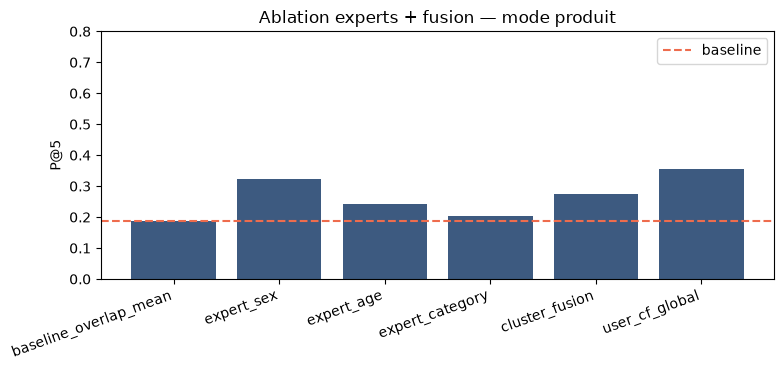

Lecture courte :
• Baseline P@5=18.8% | meilleur expert seul=expert_sex (32.2%) | fusion=27.6% | UserCF global=35.7%.
• La fusion bat la baseline mais pas le meilleur expert : les poids ou le signal démo restent limités.
• UserCF global ≥ meilleur expert démo : confirme que sexe/âge seuls sont un signal faible vs voisinage large.


In [8]:
plot_df = results.set_index("method").loc[
    ["baseline_overlap_mean", "expert_sex", "expert_age", "expert_category", "cluster_fusion", "user_cf_global"]
]

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(plot_df))
ax.bar(x, plot_df["P@5"], color="#3d5a80")
ax.axhline(plot_df.loc["baseline_overlap_mean", "P@5"], color="#ee6c4d", ls="--", label="baseline")
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, rotation=20, ha="right")
ax.set_ylabel("P@5")
ax.set_ylim(0, 0.8)
ax.set_title("Ablation experts + fusion — mode produit")
ax.legend()
plt.tight_layout()
plt.show()

fus = results.loc[results["method"] == "cluster_fusion", "P@5"].iloc[0]
best_expert = results.loc[
    results["method"].isin(["expert_sex", "expert_age", "expert_category"])
].sort_values("P@5", ascending=False).iloc[0]
base = results.loc[results["method"] == "baseline_overlap_mean", "P@5"].iloc[0]
glob = results.loc[results["method"] == "user_cf_global", "P@5"].iloc[0]

print("Lecture courte :")
print(
    f"• Baseline P@5={base:.1%} | meilleur expert seul={best_expert['method']} "
    f"({best_expert['P@5']:.1%}) | fusion={fus:.1%} | UserCF global={glob:.1%}."
)
if fus >= best_expert["P@5"] - 0.005 and fus > base:
    print("• La fusion soft bat (ou égale) les experts seuls et la baseline → assemblage utile.")
elif fus > base:
    print(
        "• La fusion bat la baseline mais pas le meilleur expert : "
        "les poids ou le signal démo restent limités."
    )
else:
    print("• La fusion ne bat pas la baseline : le découpage démo n'apporte pas assez ici.")
if best_expert["P@5"] < glob:
    print(
        "• UserCF global ≥ meilleur expert démo : confirme que sexe/âge seuls "
        "sont un signal faible vs voisinage large."
    )
